# Next-day PM2.5 forecasting for Bihar (Parts 1–5)

**Task:** at 12:00 on day d (the *issue time*), forecast PM2.5 at all 468 stations for 12:00 on
day d + 1.

**Rules we follow everywhere**
* Features use only readings at or before the issue time.
* Split by the *target* date: train = 1 Jan – 31 Aug, validation = 1 Sep – 30 Nov.
* Anything fitted (scalers, models) is fitted on training rows only.

The feature code lives in `submission/features.py`, so this notebook and the submitted
`forecast.py` use exactly the same code.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, "submission")
from features import (neighbour_sets, baseline_features, my_features, FEATURE_GROUPS,
                      FINAL_GROUPS, HISTORY_NEEDED)

SEED = 0
DATA = Path("../mp1-package/data")
FIG = Path("outputs/figures")
FIG.mkdir(parents=True, exist_ok=True)

## Load the data

In [2]:
W = pd.read_csv(DATA / "bihar_pm25_hourly_jan_nov_2024.csv", index_col="timestamp", parse_dates=True)
W.columns = W.columns.astype(str)
stations = pd.read_csv(DATA / "bihar_stations.csv", dtype={"sensor_id": str}).set_index("sensor_id")
assert list(stations.index) == list(W.columns)

A = W.to_numpy(dtype=float)        # hours x stations
times = W.index
nbrs = neighbour_sets(stations)
print(A.shape, times[0], "to", times[-1])

(8040, 468) 2024-01-01 00:00:00 to 2024-11-30 23:00:00


## Building a dataset

`build_dataset` makes one row per (target time, station). For each target time it finds the issue
time (`lead` hours earlier) and calls a feature function on the history up to that moment. It also
stores the true target and the persistence forecast (the reading at the issue time).

In [3]:
def build_dataset(feature_fn, target_times, lead=24):
    parts = []
    for target in target_times:
        p = times.get_loc(target - pd.Timedelta(hours=lead))      # row of the issue time
        X = feature_fn(A, p, times[p], nbrs)
        X["target"] = A[p + lead]
        X["persistence"] = A[p]
        X["target_time"] = target
        X["station"] = W.columns
        parts.append(X)
    return pd.concat(parts, ignore_index=True)


def noon_targets(first_issue_row):
    """All 12:00 target times whose issue time has enough history before it."""
    noon_rows = np.where(times.hour == 12)[0]
    return [times[r] for r in noon_rows if r - 24 >= first_issue_row]      # issue row = r - 24


TRAIN_END = pd.Timestamp("2024-08-31 23:59")
VAL_START = pd.Timestamp("2024-09-01")

def split(df):
    return df[df.target_time <= TRAIN_END], df[df.target_time >= VAL_START]

## Scoring
RMSE and MAE in µg/m³, over every station and every validation day, overall and per month.

In [4]:
def scores(df, prediction):
    err = prediction - df["target"].to_numpy()
    month = df["target_time"].dt.month_name().str[:3].to_numpy()
    out = {"all": (np.sqrt(np.mean(err ** 2)), np.mean(np.abs(err)))}
    for m in pd.unique(month):                    # per month (Sep, Oct, Nov for validation)
        e = err[month == m]
        out[m] = (np.sqrt(np.mean(e ** 2)), np.mean(np.abs(e)))
    return pd.DataFrame(out, index=["RMSE", "MAE"]).round(2)

# Part 1: Required baselines

1. **Persistence:** tomorrow at 12:00 = today at 12:00.
2. **Ridge:** 29 fixed features (24 hourly lags, mean of the 10 nearest stations now and over 24 h,
   network mean now, sin/cos of day of year), `Ridge(alpha=1.0)` on unscaled features, all stations
   pooled, negative forecasts clipped to 0.

In [5]:
base = build_dataset(baseline_features, noon_targets(first_issue_row=23))   # needs 24 h of history
base_train, base_val = split(base)
BASE_COLS = [c for c in base.columns if c not in ("target", "persistence", "target_time", "station")]
print("training rows:", len(base_train), f"({base_train.target_time.nunique()} days x 468 stations)")
print("validation rows:", len(base_val), f"({base_val.target_time.nunique()} days x 468 stations)")
print("features:", len(BASE_COLS))

training rows: 113256 (242 days x 468 stations)
validation rows: 42588 (91 days x 468 stations)
features: 29


In [6]:
ridge_base = Ridge(alpha=1.0).fit(base_train[BASE_COLS], base_train["target"])
pred_ridge_base = np.clip(ridge_base.predict(base_val[BASE_COLS]), 0, None)
pred_persistence = base_val["persistence"].to_numpy()

results = {"Persistence": scores(base_val, pred_persistence),
           "Ridge (29 features)": scores(base_val, pred_ridge_base)}
pd.concat(results)

all    Sep    Oct    Nov
Persistence         RMSE  32.75  23.33  20.22  47.81
                    MAE   17.47   8.91  11.97  31.70
Ridge (29 features) RMSE  29.58  20.34  19.36  43.06
                    MAE   18.16  10.35  13.46  30.81

**RMSE vs MAE.** Ridge has the lower RMSE, but persistence has the lower MAE, so neither wins on
both. Ridge is trained to minimise *squared* error. Large misses on polluted days cost it the most,
so it learns to pull forecasts towards the average: it shrinks very high readings and nudges low
ones up. That avoids the worst misses (lower RMSE), but on the many ordinary days it moves away
from today's value, which is often closer, so it collects many small errors (higher MAE).
Persistence is unbiased day to day but has occasional huge misses when the weather changes. The
per-month bias makes this visible:

In [7]:
def monthly_bias(df, prediction):
    return pd.Series(prediction - df["target"].to_numpy()).groupby(
        df["target_time"].dt.month_name().str[:3].to_numpy()).mean().round(1)

pd.DataFrame({"Persistence": monthly_bias(base_val, pred_persistence),
              "Ridge (29 features)": monthly_bias(base_val, pred_ridge_base)})

,Persistence,Ridge (29 features)
Nov,-0.6,3.5
Oct,-0.8,6.9
Sep,-0.0,5.5


# Part 2: Improving the forecast

### Ideas
* **Work in log space.** PM2.5 changes multiplicatively. A typical day-to-day change is a
  percentage, and the spread is far larger in winter than in summer. All our features are
  `log(1 + PM2.5)`.
* **Predict the change, not the level.** The target is the log change from today's reading,
  `z = log(1 + y_tomorrow) − log(1 + y_today)`. The forecast is then today's value times a
  learned factor, so regularisation pulls the model towards persistence instead of towards a
  global average.
* **Bias correction.** `exp` of a predicted *mean log* gives a value that is too low on average.
  We multiply by `exp(σ²/2)`, where σ² is the variance of the training residuals (the standard
  "smearing" correction for a lognormal).

### Feature groups (all from data at or before the issue time)
We tried eight groups. `variability` was added after looking at where the error comes from: most of it is sudden
local jumps on polluted days, so we describe how unsettled the air is. The selection below decides which groups stay.
| group | features | what it captures |
|---|---|---|
| recent_hours | 24 | the station's last 24 hourly readings |
| neighbourhood | 6 | mean of the 10 nearest stations, and of stations within 15 km and 40 km, now and over the last 24 h |
| network | 4 | state-wide mean now, over 24 h and over 7 days, and its 24 h change |
| calendar | 3 | sin/cos of the day of year, weekend |
| station_level | 2 | the station's 30-day mean, and that mean relative to the state |
| past_days | 13 | the same hour on the previous 6 days, and the last 7 daily means |
| trends | 3 | change over the last 3, 6 and 24 h |
| variability | 2 | the station's ups and downs (std) over the last 24 h, and the 24 h change of its 10 nearest neighbours |

In [8]:
def all_groups_features(A, p, t, nbrs):
    return my_features(A, p, t, nbrs, groups=list(FEATURE_GROUPS))

# Our features need a week of history, so the first issue time is 8 Jan 12:00. That leaves
# 236 training days (110,448 rows): every noon target from 9 Jan to 31 Aug at every station.
data = build_dataset(all_groups_features, noon_targets(first_issue_row=HISTORY_NEEDED - 1))
train, val = split(data)

# Column names of each group (call each group function once on a small piece of history)
L_sample = np.log1p(A[:HISTORY_NEEDED])
GROUP_COLS = {g: list(fn(L_sample, HISTORY_NEEDED - 1, times[HISTORY_NEEDED - 1], nbrs))
              for g, fn in FEATURE_GROUPS.items()}
print({g: len(c) for g, c in GROUP_COLS.items()})
print("training rows:", len(train), f"({train.target_time.nunique()} days)",
      "| validation rows:", len(val))

{'recent_hours': 24, 'neighbourhood': 6, 'network': 4, 'calendar': 3, 'station_level': 2, 'past_days': 13, 'trends': 3, 'variability': 2, 'sectors': 8}
training rows: 110448 (236 days) | validation rows: 42588


### The model
`fit_log_change` trains any scikit-learn regressor on the log-change target and returns a
function that turns features into PM2.5 forecasts.

In [9]:
def log_change_target(df):
    return np.log1p(df["target"]) - np.log1p(df["persistence"])


def fit_log_change(model, df, cols):
    model.fit(df[cols], log_change_target(df))
    residuals = log_change_target(df) - model.predict(df[cols])
    smear = residuals.var() / 2                                   # bias correction, see above

    def predict(new_df):
        log_forecast = np.log1p(new_df["persistence"]) + model.predict(new_df[cols]) + smear
        return np.clip(np.expm1(log_forecast).to_numpy(), 0, None)
    return predict


def ridge_model(alpha):
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha))    # scaler is fitted on train only


def cols_for(groups):
    return [c for g in groups for c in GROUP_COLS[g]]

### Step 1: which groups help? (ridge, alpha = 100 to start)
We start with all eight groups and remove one at a time. A group whose removal *lowers* the
validation RMSE is hurting, so we drop it and repeat.

In [10]:
def val_rmse(groups, alpha=100):
    predict = fit_log_change(ridge_model(alpha), train, cols_for(groups))
    return scores(val, predict(val)).loc["RMSE", "all"]


def backward_elimination(alpha):
    groups = list(FEATURE_GROUPS)
    current = val_rmse(groups, alpha)
    print(f"alpha {alpha}, all groups:", current)
    while True:
        without = {g: val_rmse([x for x in groups if x != g], alpha) for g in groups}
        worst = min(without, key=without.get)
        if without[worst] >= current:
            break
        groups.remove(worst)
        current = without[worst]
        print(f"  -> drop '{worst}', validation RMSE now {current}")
    print("  kept:", groups)
    return groups

groups = backward_elimination(100)

alpha 100, all groups: 28.98


  -> drop 'past_days', validation RMSE now 28.28


  -> drop 'neighbourhood', validation RMSE now 28.26


  kept: ['recent_hours', 'network', 'calendar', 'station_level', 'trends', 'variability', 'sectors']


With alpha = 100, removing `past_days` lowers the validation RMSE; nothing else does.
The differences at this step are small (a few hundredths), so the choice can depend on alpha.
Step 2 therefore repeats the selection with the tuned alpha, and there `trends` is dropped too.

### Step 2: tune alpha, and choose groups and alpha together
The best groups can depend on alpha, so we repeat: tune alpha for the current groups, redo the
group selection with that alpha, and stop when neither changes (validation only). Where two
alphas are within a few hundredths, we take the larger one: stronger regularisation is safer for
a new month.

In [11]:
alphas = [1, 10, 100, 300, 1000, 3000, 10000]
alpha = 100
while True:
    alpha_rmse = {a: val_rmse(groups, a) for a in alphas}
    print(alpha_rmse)
    best = min(alpha_rmse, key=alpha_rmse.get)
    if best == alpha:
        break
    alpha = best
    groups = backward_elimination(alpha)
print("final groups:", groups, "| best alpha on validation:", alpha)

# alpha = 100 and 300 tie on validation; we use the stronger regularisation (300), which is
# safer when forecasting a new month (December).
assert alpha_rmse[300] - alpha_rmse[alpha] < 0.05
BEST_ALPHA = 300
print("SELECTED GROUPS:", groups)
assert groups == FINAL_GROUPS
FINAL_COLS = cols_for(FINAL_GROUPS)

{1: np.float64(28.28), 10: np.float64(28.28), 100: np.float64(28.26), 300: np.float64(28.26), 1000: np.float64(28.33), 3000: np.float64(28.51), 10000: np.float64(28.63)}
final groups: ['recent_hours', 'network', 'calendar', 'station_level', 'trends', 'variability', 'sectors'] | best alpha on validation: 100
SELECTED GROUPS: ['recent_hours', 'network', 'calendar', 'station_level', 'trends', 'variability', 'sectors']


### Step 3: does a more flexible model do better?
A random forest on the same features and the same log-change target.

In [12]:
forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=20, max_features=0.33,
                               n_jobs=-1, random_state=SEED)
predict_forest = fit_log_change(forest, train, FINAL_COLS)
predict_ridge = fit_log_change(ridge_model(BEST_ALPHA), train, FINAL_COLS)

flex = pd.DataFrame({
    "train RMSE": [scores(train, predict_ridge(train)).loc["RMSE", "all"],
                   scores(train, predict_forest(train)).loc["RMSE", "all"]],
    "validation RMSE": [scores(val, predict_ridge(val)).loc["RMSE", "all"],
                        scores(val, predict_forest(val)).loc["RMSE", "all"]],
}, index=["Ridge", "Random forest"])
flex

,train RMSE,validation RMSE
Ridge,26.50,28.26
Random forest,19.01,33.47


The forest fits the training months much better than ridge (train RMSE about 19 vs 27) but is much
worse on validation (about 36 vs 28.5), so it is overfitting. With 41 features and a few hundred
training days, it learns patterns specific to Jan–Aug, such as how winter smog cleared in February
and how calm the monsoon was. Those patterns don't carry over to the build-up of smog in Oct–Nov, a
season that is absent from training. Trees also cannot predict outside the range of targets they
have seen. Ridge's single smooth rule ("about today's level, adjusted by neighbours, the state-wide
level and the trend") transfers better. We keep **ridge** as the final model.

### Step 4: mix the forecast with persistence
A weighted average of our forecast and persistence (today's reading). The weight is chosen on
validation. This hedges the model's factor towards today's value, which helps when the model
over-reacts.

In [13]:
pred_model = predict_ridge(val)
blend_rmse = {w: scores(val, w * pred_model + (1 - w) * val["persistence"].to_numpy()).loc["RMSE", "all"]
              for w in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]}
print(blend_rmse)
BLEND = min(blend_rmse, key=blend_rmse.get)
print("best weight on our model:", BLEND)

{0.5: np.float64(28.92), 0.6: np.float64(28.51), 0.7: np.float64(28.24), 0.8: np.float64(28.1), 0.9: np.float64(28.11), 1.0: np.float64(28.26)}
best weight on our model: 0.8


### Step 5: state-wide bias correction
Operational air-quality forecasts (e.g. NOAA's PM2.5 forecasts) correct each new forecast with the
recent forecast error ("Kalman-filter" or running bias correction). We use the simplest version.
At the issue time we already know how wrong *yesterday's* forecast was, because its target is the
reading at the issue time. We take the state-wide mean of that error (in log space) and add
`LAMBDA` times it to today's forecast. Nothing is refitted: `LAMBDA` is fixed, and the error is
computed from readings at or before the issue time, like any other feature.

We choose `LAMBDA` on Sep–Oct only and then check it on November, which it has not seen.

In [14]:
def yesterday_state_error(df, predict):
    """For each target day T: the state-mean log error of the forecast for T - 1 day, which is
    known at the issue time of T (its target is the reading at that issue time)."""
    err = np.log1p(df["target"]) - np.log1p(predict(df))
    daily = err.groupby(df["target_time"]).mean()
    return daily.shift(1, freq="D")


STATE_ERR = yesterday_state_error(pd.concat([train, val]), predict_ridge)


def predict_final(df, lam=None):
    """Our final forecast: ridge + state-wide bias correction, then mixed with persistence."""
    lam = LAMBDA if lam is None else lam
    correction = STATE_ERR.reindex(df["target_time"]).fillna(0).to_numpy()
    corrected = np.expm1(np.log1p(predict_ridge(df)) + lam * correction)
    return BLEND * corrected + (1 - BLEND) * df["persistence"].to_numpy()


lambdas = [0, 0.1, 0.2, 0.3, 0.4, 0.5]
sep_oct, nov = val[val.target_time.dt.month <= 10], val[val.target_time.dt.month == 11]
lam_rmse = {l: scores(sep_oct, predict_final(sep_oct, l)).loc["RMSE", "all"] for l in lambdas}
print("Sep-Oct RMSE by lambda:", lam_rmse)
LAMBDA = min(lam_rmse, key=lam_rmse.get)
print("chosen lambda:", LAMBDA)
pd.concat({"November, no correction": scores(nov, predict_final(nov, 0)),
           f"November, lambda = {LAMBDA}": scores(nov, predict_final(nov))})

Sep-Oct RMSE by lambda: {0: np.float64(18.62), 0.1: np.float64(18.57), 0.2: np.float64(18.54), 0.3: np.float64(18.53), 0.4: np.float64(18.54), 0.5: np.float64(18.57)}
chosen lambda: 0.3


all    Nov
November, no correction RMSE  41.12  41.12
                        MAE   28.42  28.42
November, lambda = 0.3  RMSE  40.69  40.69
                        MAE   28.04  28.04

The correction helps mainly during the Oct–Nov build-up, when a model trained on Jan–Aug is wrong
in the same direction several days in a row. On the training months the model has no lasting bias,
so there it does not help. December is again a new month for the final model, which is the case
the correction is made for. It cannot foresee a sudden clean-up like 29 Nov.

### Ablation of the final model
Starting from the final model (6 groups, best alpha, before mixing), we remove one group at a time,
retrain with the same hyperparameters, and record the change in validation RMSE. A positive change
means the group was helping. Every kept group helps.

**What each group adds.** `recent_hours` carries most of the skill, and without it the model has
almost nothing to anchor on. `calendar` is second: it tells the model where in the seasonal cycle
it is. Training contains no Sep–Dec dates, so this is partly extrapolation; December (cos ≈ 1,
sin ≈ 0) at least resembles early January, which is in training. `station_level` and `network` add
smaller gains. `neighbourhood` and `variability` add very little (under 0.1 each), because nearby
stations mostly move together with the station itself and with the state-wide level, which other
groups already cover.

**Groups that did not help.** `past_days` and `trends` were dropped: the 24 hourly readings and the
30-day station level already carry the same information, and a linear model can form "now minus
3 hours" from the hourly lags by itself.

**Information we don't have that would help most:** a weather forecast, especially wind, boundary
layer height, rain and temperature inversions. Day-to-day changes in PM2.5 are driven mainly by
weather. Fire counts from satellites (crop-residue burning in Oct–Nov) would also help.

In [15]:
final_rmse = val_rmse(FINAL_GROUPS, BEST_ALPHA)
ablation = pd.DataFrame([
    {"group removed": g, "features": len(GROUP_COLS[g]),
     "validation RMSE": val_rmse([x for x in FINAL_GROUPS if x != g], BEST_ALPHA)}
    for g in FINAL_GROUPS
])
ablation["change vs final"] = (ablation["validation RMSE"] - final_rmse).round(2)
print("final model validation RMSE:", final_rmse)
ablation

final model validation RMSE: 28.26


,group removed,features,validation RMSE,change vs final
0,recent_hours,24,29.76,1.50
1,network,4,28.56,0.30
2,calendar,3,29.62,1.36
3,station_level,2,28.86,0.60
4,trends,3,28.26,0.00
5,variability,2,28.29,0.03
6,sectors,8,28.52,0.26


### Final validation results, next to the baselines
The baselines are scored on the same 91 × 468 validation rows as our model.

In [16]:
assert (val["target_time"].to_numpy() == base_val["target_time"].to_numpy()).all()
pred_final = predict_final(val)
results["Our model, before mixing"] = scores(val, predict_ridge(val))
results["Our model, mixed, no bias correction"] = scores(val, predict_final(val, 0))
results["Our model (final)"] = scores(val, pred_final)
pd.concat(results)

all    Sep    Oct    Nov
Persistence                          RMSE  32.75  23.33  20.22  47.81
                                     MAE   17.47   8.91  11.97  31.70
Ridge (29 features)                  RMSE  29.58  20.34  19.36  43.06
                                     MAE   18.16  10.35  13.46  30.81
Our model, before mixing             RMSE  28.26  20.58  17.36  41.07
                                     MAE   15.84   8.04  10.95  28.70
Our model, mixed, no bias correction RMSE  28.10  19.98  17.19  41.12
                                     MAE   15.67   7.95  10.80  28.42
Our model (final)                    RMSE  27.86  20.02  16.98  40.69
                                     MAE   15.39   7.82  10.49  28.04

Our final model beats both baselines on **both** RMSE and MAE, overall and in every month.
Mixing with persistence (weight 0.9 on the model) gives a small gain, and the state-wide bias
correction a larger one. The improvement over ridge is real but modest: without weather
information, a day-ahead forecast can't anticipate most day-to-day changes.

# Part 3: Lead time
The target stays at 12:00 on day d + 1, and the issue time moves closer: 24, 12, 6, 3 and 1 hours
before. Every model is refitted for each lead, with all features taken relative to the new issue
time.

In [17]:
LEADS = [24, 12, 6, 3, 1]
lead_rows = []
for lead in LEADS:
    b = build_dataset(baseline_features, noon_targets(first_issue_row=23), lead=lead)
    b_train, b_val = split(b)
    ridge_b = Ridge(alpha=1.0).fit(b_train[BASE_COLS], b_train["target"])

    m = build_dataset(my_features, noon_targets(first_issue_row=HISTORY_NEEDED - 1), lead=lead)
    m_train, m_val = split(m)
    ours_ridge = fit_log_change(ridge_model(BEST_ALPHA), m_train, FINAL_COLS)
    # Part 3 compares the models without the Step 5 bias correction (same rule at every lead)
    ours = lambda df: BLEND * ours_ridge(df) + (1 - BLEND) * df["persistence"].to_numpy()

    ridge_b_predict = lambda df: np.clip(ridge_b.predict(df[BASE_COLS]), 0, None)
    for name, df_train, df_val, predict in [
            ("Persistence", b_train, b_val, lambda df: df["persistence"].to_numpy()),
            ("Ridge (29 features)", b_train, b_val, ridge_b_predict),
            ("Our model", m_train, m_val, ours)]:
        s = scores(df_val, predict(df_val))
        lead_rows.append({"lead (h)": lead, "method": name,
                          "RMSE": s.loc["RMSE", "all"], "MAE": s.loc["MAE", "all"],
                          "train RMSE": scores(df_train, predict(df_train)).loc["RMSE", "all"]})

lead_table = pd.DataFrame(lead_rows)
lead_table.pivot(index="lead (h)", columns="method", values="RMSE")

method,Our model,Persistence,Ridge (29 features)
lead (h),,,
1,19.58,23.95,18.95
3,34.05,51.43,28.37
6,42.28,66.82,33.72
12,39.32,72.74,31.70
24,28.10,32.75,29.58


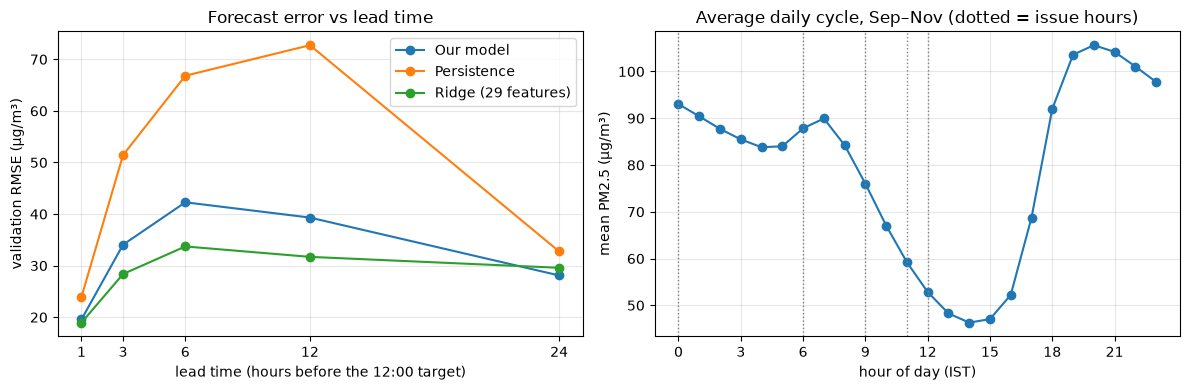

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, g in lead_table.groupby("method"):
    ax[0].plot(g["lead (h)"], g["RMSE"], marker="o", label=name)
ax[0].set_xticks(LEADS)
ax[0].set_xlabel("lead time (hours before the 12:00 target)")
ax[0].set_ylabel("validation RMSE (µg/m³)")
ax[0].set_title("Forecast error vs lead time")
ax[0].legend()
ax[0].grid(alpha=0.3)

hourly_profile = W[W.index >= VAL_START].mean(axis=1).groupby(lambda t: t.hour).mean()
ax[1].plot(hourly_profile.index, hourly_profile.values, marker="o")
for lead in LEADS:
    ax[1].axvline((12 - lead) % 24, color="grey", ls=":", lw=1)
ax[1].set_xticks(range(0, 24, 3))
ax[1].set_xlabel("hour of day (IST)")
ax[1].set_ylabel("mean PM2.5 (µg/m³)")
ax[1].set_title("Average daily cycle, Sep–Nov (dotted = issue hours)")
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "lead_time.png", dpi=120)
plt.show()

**1-hour lead (nowcast) vs day-ahead**

In [19]:
lead_table[lead_table["lead (h)"].isin([1, 24])].pivot(index="method", columns="lead (h)", values=["RMSE", "MAE"])

RMSE           MAE       
lead (h)                1      24     1      24
method                                         
Our model            19.58  28.10   8.72  15.67
Persistence          23.95  32.75  10.36  17.47
Ridge (29 features)  18.95  29.58   8.67  18.16

**Persistence is not monotonic.** Its error does not simply grow with lead time. It is smallest at
1 h, rises steeply to a maximum at 12 h, then falls again at 24 h, back to nearly the 1-hour
level. The reason is the daily cycle (right panel). Persistence copies the value at the issue hour,
so it only works if that hour looks like 12:00. Midnight and 06:00 sit near the night-time peak,
far above the noon level, so copying them overshoots badly. 24 hours earlier is 12:00 again, the
same point in the cycle, so persistence recovers.

**The learned models show a weaker version of the same hump.** They are refitted for each lead,
so they learn that night values must be scaled down to reach noon, and their 3–12 h errors are
far below persistence's. Yet they are still *worse* at 6 h than at 24 h, even though they have more
recent information. The training RMSE shows why:

In [20]:
lead_table.pivot(index="lead (h)", columns="method", values="train RMSE")

method,Our model,Persistence,Ridge (29 features)
lead (h),,,
1,17.13,22.68,17.80
3,23.93,47.40,23.61
6,25.69,53.99,24.95
12,26.92,62.23,25.71
24,26.69,32.91,28.00


In [21]:
night_to_noon = W.groupby([W.index.month, W.index.hour]).mean().mean(axis=1).unstack()
(night_to_noon[[0, 6, 9]].div(night_to_noon[12], axis=0)).round(2).rename_axis(index="month", columns=None).rename(
    columns=lambda h: f"{h:02d}:00 / 12:00")

,00:00 / 12:00,06:00 / 12:00,09:00 / 12:00
month,,,
1,1.39,1.15,1.22
2,1.96,1.80,1.78
3,2.47,2.46,2.04
4,2.47,1.91,1.21
5,1.83,2.08,1.39
6,1.38,1.51,1.28
7,1.14,1.22,1.14
8,1.11,1.12,1.06
9,1.54,1.51,1.20


On the *training* months the shorter leads are more accurate, as expected (6 h: about 24 vs 24 h:
about 27). On validation the order flips. The table above explains this. A forecast issued at night
has to convert a night value into a noon value, and the night-to-noon ratio is not stable. It
swings from about 1.1 (Jul–Aug) to about 2.5 (Mar–Apr) between months, and from day to day with the
weather (how fast the morning sun mixes the air). A pooled linear model learns one average
conversion, which is wrong on many validation days, and the error grows. A noon-to-noon forecast
needs no conversion at all. So the hump in the learned models is a weaker echo of the persistence
hump, caused by the same daily cycle.

**Choosing a lead for a public warning.** A 1-hour nowcast is the most accurate (RMSE about 19),
but it gives people no time to act. A warning issued at 12:00 for the next day gives a full day to
plan, for example closing schools or moving outdoor work, at the cost of a larger error (RMSE
about 28). We'd choose the 24-hour lead. Shorter leads such as 6 hours are both less useful *and*,
here, not more accurate.

# Part 4: Forecast maps vs observed maps
Station values are interpolated to the 0.05° grid by inverse-distance weighting (power 2, all
stations). The same weights are used for observed and forecast values, so any difference between
the maps comes from the forecasts alone.

In [22]:
grid = pd.read_csv(DATA / "bihar_grid_005deg.csv")
outline = pd.read_csv(DATA / "bihar_boundary.csv")

def to_km(lat, lon):
    return (lon - 85.5) * 100.3, (lat - 25.7) * 110.6

gx, gy = to_km(grid.latitude.to_numpy(), grid.longitude.to_numpy())
sx, sy = to_km(stations.latitude.to_numpy(), stations.longitude.to_numpy())
dist = np.sqrt((gx[:, None] - sx[None, :]) ** 2 + (gy[:, None] - sy[None, :]) ** 2)
idw_weights = 1 / np.maximum(dist, 0.01) ** 2               # avoid division by zero
idw_weights /= idw_weights.sum(axis=1, keepdims=True)       # each grid row sums to 1

def idw(station_values):
    return idw_weights @ station_values                     # 3,396 grid values

print("grid points:", len(grid), "| weight matrix:", idw_weights.shape)

grid points: 3396 | weight matrix: (3396, 468)


### Map scores for every validation day

In [23]:
val_days = val["target_time"].unique()
n_st = len(stations)
day_rows = []
for i, day in enumerate(val_days):
    rows = slice(i * n_st, (i + 1) * n_st)               # the 468 rows of this day
    obs = val["target"].to_numpy()[rows]
    obs_map = idw(obs)
    for name, pred in [("Persistence", val["persistence"].to_numpy()[rows]), ("Our model", pred_final[rows])]:
        f_map = idw(pred)
        day_rows.append({
            "day": day, "method": name,
            "station RMSE": np.sqrt(np.mean((pred - obs) ** 2)),
            "map RMSE": np.sqrt(np.mean((f_map - obs_map) ** 2)),
            "pattern correlation": np.corrcoef(f_map, obs_map)[0, 1],
        })
daily = pd.DataFrame(day_rows)
daily.groupby("method")[["station RMSE", "map RMSE", "pattern correlation"]].mean().round(3)

,station RMSE,map RMSE,pattern correlation
method,,,
Our model,24.327,13.407,0.622
Persistence,28.568,15.369,0.580


Note that the mean of the daily station RMSEs is not the same number as the overall RMSE in
Part 2, which pools all days before taking the square root.

### Three example days

{'clean day': '2024-09-15 12:00:00', 'polluted day': '2024-11-27 12:00:00', 'our worst day': '2024-11-29 12:00:00'}


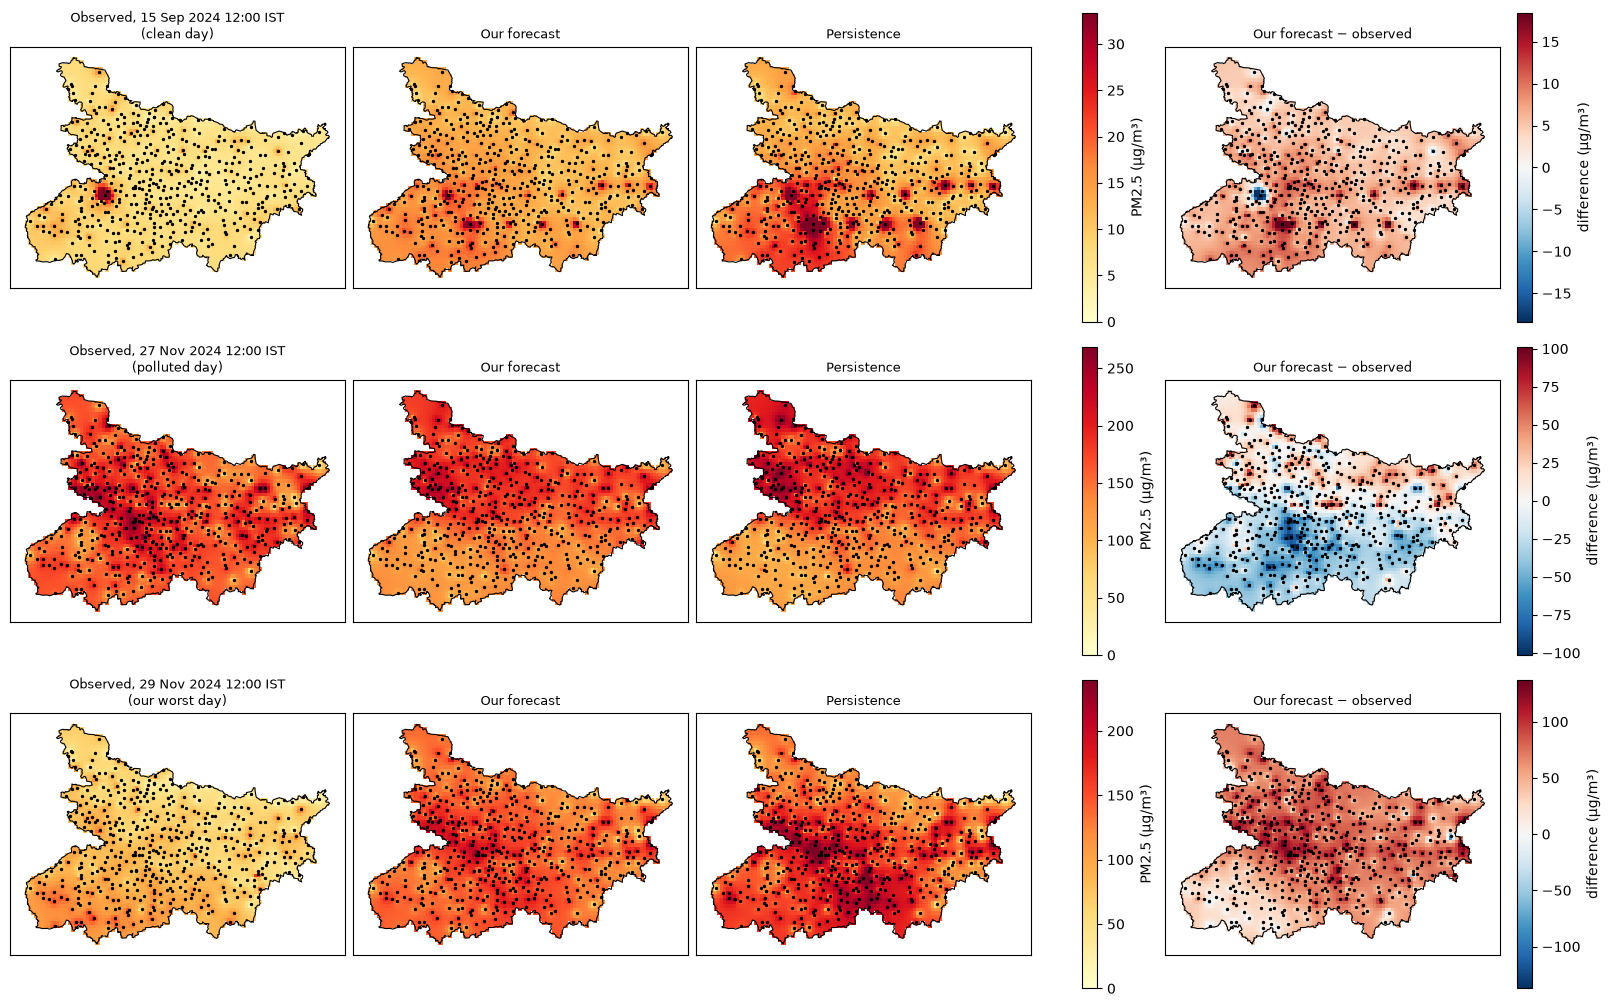

In [24]:
network_mean = val.groupby("target_time")["target"].mean()
ours_daily = daily[daily.method == "Our model"].set_index("day")["station RMSE"]
example_days = {
    "clean day": network_mean.idxmin(),
    "polluted day": network_mean.idxmax(),
    "our worst day": ours_daily.idxmax(),
}
print({k: str(v) for k, v in example_days.items()})

def draw_map(ax, values, title, cmap, vmin, vmax):
    sc = ax.scatter(grid.longitude, grid.latitude, c=values, cmap=cmap, vmin=vmin, vmax=vmax,
                    s=9, marker="s", linewidths=0)
    ax.plot(outline.longitude, outline.latitude, color="black", lw=0.8)
    ax.scatter(stations.longitude, stations.latitude, s=2, color="black", label="station")
    ax.set_title(title, fontsize=9)
    ax.set_aspect(1 / np.cos(np.radians(25.7)))
    ax.set_xticks([]); ax.set_yticks([])
    return sc

fig, axes = plt.subplots(3, 4, figsize=(16, 10), layout="constrained")
for row, (label, day) in enumerate(example_days.items()):
    i = list(val_days).index(day)
    rows = slice(i * n_st, (i + 1) * n_st)
    obs_map = idw(val["target"].to_numpy()[rows])
    our_map = idw(pred_final[rows])
    per_map = idw(val["persistence"].to_numpy()[rows])
    vmax = np.percentile(np.concatenate([obs_map, our_map, per_map]), 99)
    date = pd.Timestamp(day).strftime("%d %b %Y 12:00 IST")

    sc = draw_map(axes[row, 0], obs_map, f"Observed, {date}\n({label})", "YlOrRd", 0, vmax)
    draw_map(axes[row, 1], our_map, "Our forecast", "YlOrRd", 0, vmax)
    draw_map(axes[row, 2], per_map, "Persistence", "YlOrRd", 0, vmax)
    fig.colorbar(sc, ax=axes[row, :3], label="PM2.5 (µg/m³)")
    lim = np.percentile(np.abs(our_map - obs_map), 99)        # same clipping idea as vmax
    dc = draw_map(axes[row, 3], our_map - obs_map, "Our forecast − observed", "RdBu_r", -lim, lim)
    fig.colorbar(dc, ax=axes[row, 3], label="difference (µg/m³)")
plt.savefig(FIG / "maps.png", dpi=110)
plt.show()

**Map RMSE vs station RMSE.** The map RMSE is lower, because IDW averages neighbouring stations
and smooths away much of the station-level noise in both maps. The accuracy to quote is the
**station RMSE**, since it compares forecasts with real measurements. The map RMSE compares two
interpolations.

**The observed map is not ground truth.** Between stations it is a weighted average of nearby
stations, not a measurement. It cannot show a hotspot that falls between sensors. It is smoothest
where stations are sparse (the edges of the state), and it inherits sensor errors and the
upstream gap-filling in the data.

**Good pattern correlation with poor RMSE.** A forecast that gets the *shape* right (which
districts are worst) but the *level* wrong, for example everything 40% too low on a smog day, has
a correlation near 1 but a large RMSE. For a public warning the level matters more. Warnings are
issued when PM2.5 crosses fixed thresholds, so a forecast that is too low everywhere misses the
warning even if its pattern is perfect.

# Part 5: Final model for the hidden December test
We refit the final model (same features, same alpha, same mixing weight, same bias-correction weight) on **all** targets up to 30 Nov, and save it
for `submission/forecast.py`.
The model is saved as plain numpy arrays, so `forecast.py` does not depend on the scikit-learn
version used for grading.


In [25]:
import joblib

full = pd.concat([train, val])
final_model = ridge_model(BEST_ALPHA).fit(full[FINAL_COLS], log_change_target(full))
smear = (log_change_target(full) - final_model.predict(full[FINAL_COLS])).var() / 2

# Save plain numpy arrays rather than the scikit-learn objects, so forecast.py works with any
# scikit-learn version on the grader's machine: prediction = ((x - mean) / scale) @ coef + intercept.
scaler, ridge = final_model.named_steps["standardscaler"], final_model.named_steps["ridge"]
joblib.dump({"columns": FINAL_COLS, "mean": scaler.mean_, "scale": scaler.scale_,
             "coef": ridge.coef_, "intercept": float(ridge.intercept_), "smear": float(smear),
             "blend": float(BLEND), "lambda": float(LAMBDA)},
            "submission/model.pkl")
print("refit on", len(full), "rows; saved submission/model.pkl")

refit on 153036 rows; saved submission/model.pkl


Run the official checker on the submission folder, from the package root:
```
cd ../mp1-package
python starter/check_submission.py ../mp1-solution/submission
```